In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/processed/customers_clean.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset shape: (7043, 21)

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
print(df.isnull().sum().sort_values(ascending=False))

TotalCharges        11
gender               0
SeniorCitizen        0
Partner              0
customerID           0
Dependents           0
tenure               0
MultipleLines        0
PhoneService         0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
InternetService      0
TechSupport          0
StreamingTV          0
Contract             0
StreamingMovies      0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
Churn                0
dtype: int64


In [4]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [5]:
print(df["Churn"].value_counts(dropna=False))

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [6]:
# Remove rows with missing target values
df = df.dropna(subset=["Churn"]).copy()

# Convert target to numeric labels
y = (
    df["Churn"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"yes": 1, "no": 0})
)

if y.isna().any():
    raise ValueError("Unexpected values found in Churn.")

# Remove the target and customer ID from the features
X = df.drop(columns=["Churn", "customerID"], errors="ignore")

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget examples:")
print(y.head())

Features shape: (7043, 19)
Target shape: (7043,)

Target examples:
0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\Admin\AppData\Local\Temp\ipykernel_3884\2270116174.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [9]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data:", X_train_processed.shape)
print("Testing data:", X_test_processed.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (5634, 45)
Testing data: (1409, 45)
Training labels: (5634,)
Testing labels: (1409,)


In [11]:
from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
model.fit(X_train_processed, y_train)

print("Model training completed!")

Model training completed!


In [12]:
# Predict customer churn
y_pred = model.predict(X_test_processed)

# Estimate churn probabilities
y_prob = model.predict_proba(X_test_processed)[:, 1]

print("Actual outcomes:")
print(y_test.head(10).tolist())

print("\nPredicted outcomes:")
print(y_pred[:10].tolist())

print("\nPredicted churn probabilities:")
print(y_prob[:10].round(3).tolist())

Actual outcomes:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

Predicted outcomes:
[0, 1, 0, 0, 0, 1, 0, 0, 0, 0]

Predicted churn probabilities:
[0.045, 0.684, 0.059, 0.402, 0.022, 0.604, 0.449, 0.13, 0.003, 0.395]


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.806
Precision: 0.657
Recall: 0.559
F1-score: 0.604
ROC-AUC: 0.842

Confusion Matrix:
[[926 109]
 [165 209]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [14]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_processed, y_train)

baseline_pred = baseline.predict(X_test_processed)

print("Baseline accuracy:",
      round(accuracy_score(y_test, baseline_pred), 3))

print("Logistic Regression accuracy:",
      round(accuracy_score(y_test, y_pred), 3))

print("\nBaseline recall:",
      round(recall_score(y_test, baseline_pred, zero_division=0), 3))

print("Logistic Regression recall:",
      round(recall_score(y_test, y_pred, zero_division=0), 3))

Baseline accuracy: 0.735
Logistic Regression accuracy: 0.806

Baseline recall: 0.0
Logistic Regression recall: 0.559


In [15]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [16]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Predictions from both models
lr_pred = model.predict(X_test_processed)
lr_prob = model.predict_proba(X_test_processed)[:, 1]

rf_pred = rf_model.predict(X_test_processed)
rf_prob = rf_model.predict_proba(X_test_processed)[:, 1]


def evaluate_model(name, y_true, predictions, probabilities):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }


results = pd.DataFrame([
    evaluate_model(
        "Logistic Regression", y_test, lr_pred, lr_prob
    ),
    evaluate_model(
        "Random Forest", y_test, rf_pred, rf_prob
    )
])

print(results.round(3).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
Logistic Regression     0.806      0.657   0.559     0.604    0.842
      Random Forest     0.759      0.531   0.775     0.630    0.841


In [17]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    predictions = (rf_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df.round(3).to_string(index=False))

 Threshold  Precision  Recall  F1-score
       0.3      0.433   0.901     0.585
       0.4      0.485   0.837     0.614
       0.5      0.531   0.775     0.630
       0.6      0.580   0.652     0.614
       0.7      0.662   0.529     0.588


In [20]:
results.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

In [21]:
import pandas as pd

# Get the names of the transformed features
feature_names = preprocessor.get_feature_names_out()

# Get importance scores from the trained Random Forest
importance_scores = rf_model.feature_importances_

# Create a table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15).to_string(index=False))

                                         Feature  Importance
                                 numeric__tenure    0.127022
            categorical__Contract_Month-to-month    0.123829
                           numeric__TotalCharges    0.103262
                         numeric__MonthlyCharges    0.068909
                  categorical__OnlineSecurity_No    0.065688
                  categorical__Contract_Two year    0.063577
                     categorical__TechSupport_No    0.053611
        categorical__InternetService_Fiber optic    0.047253
     categorical__PaymentMethod_Electronic check    0.038165
                categorical__InternetService_DSL    0.020312
                    categorical__OnlineBackup_No    0.019255
                  categorical__Contract_One year    0.018565
                 categorical__OnlineSecurity_Yes    0.014080
                    categorical__TechSupport_Yes    0.012439
categorical__StreamingMovies_No internet service    0.012375


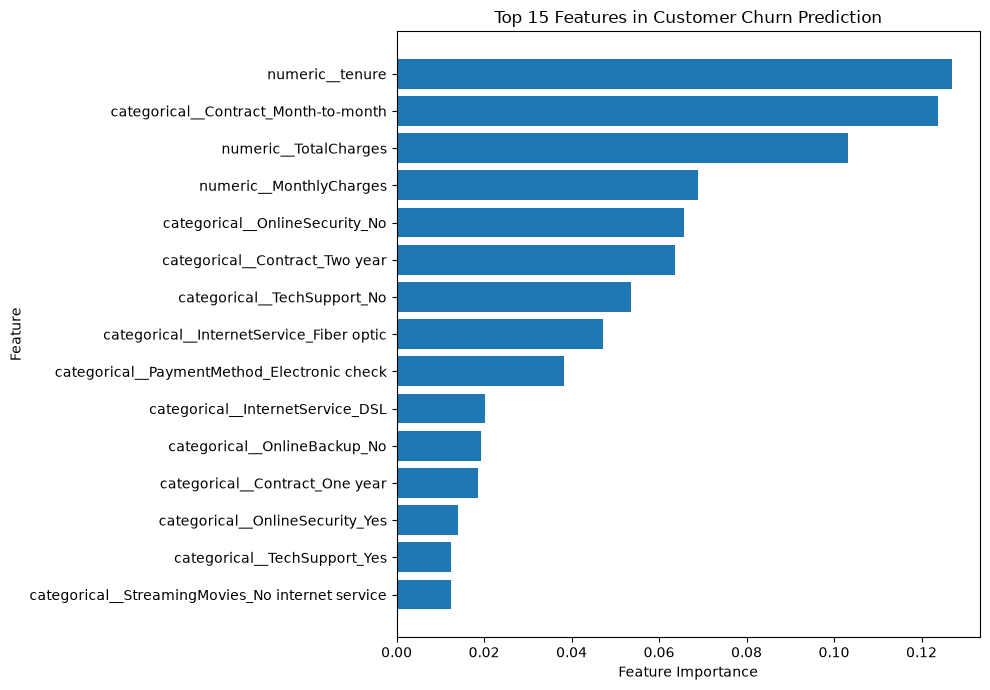

In [22]:
import matplotlib.pyplot as plt
import os

top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features in Customer Churn Prediction")
plt.tight_layout()

os.makedirs("../reports/figures", exist_ok=True)

plt.savefig(
    "../reports/figures/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    rf_model,
    X_test_processed,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
}).sort_values(
    by="Importance",
    ascending=False
)

print(permutation_df.head(15).to_string(index=False))

                                          Feature  Importance      Std
                                  numeric__tenure    0.025723 0.001334
             categorical__Contract_Month-to-month    0.022333 0.002562
                            numeric__TotalCharges    0.016801 0.001524
                   categorical__Contract_Two year    0.008079 0.001572
         categorical__InternetService_Fiber optic    0.005033 0.004291
                   categorical__OnlineSecurity_No    0.002015 0.001426
                      categorical__TechSupport_No    0.001725 0.000684
                   categorical__Contract_One year    0.001095 0.002006
                           numeric__SeniorCitizen    0.000616 0.000511
                 categorical__InternetService_DSL    0.000576 0.002703
                      categorical__Dependents_Yes    0.000508 0.000464
     categorical__TechSupport_No internet service    0.000282 0.000567
categorical__DeviceProtection_No internet service    0.000270 0.000383
      